#  Genetic Programming: ewolucja programu w drzewach AST

Spektakularny pokaz programowania genetycznego: **nie podajemy wzoru**, tylko przykłady wejście → wyjście.

Ukryty cel demonstracji:

\[
y = x^3 - 2x^2 + 3x + 5
\]

Algorytm nie zna tego wzoru. Ma go **wyhodować** z losowych drzew programu.

Proces:

**populacja → fitness → selekcja → krzyżowanie → mutacja → nowe pokolenie**

In [1]:
import random
import math
import ast
import copy
from dataclasses import dataclass

SEED = 10
random.seed(SEED)

# Dane uczące. Wzór poniżej służy WYŁĄCZNIE do przygotowania przykładów.
X = list(range(-5, 6))
Y = [x**3 - 2*x*x + 3*x + 5 for x in X]

print("Algorytm dostaje tylko te pary:")
list(zip(X, Y))

Algorytm dostaje tylko te pary:


[(-5, -185),
 (-4, -103),
 (-3, -49),
 (-2, -17),
 (-1, -1),
 (0, 5),
 (1, 7),
 (2, 11),
 (3, 23),
 (4, 49),
 (5, 95)]

## 1. Reprezentacja osobnika

Każdy osobnik jest drzewem wyrażenia matematycznego.

Przykład:

```text
        +
       / \
      *   3
     / \
    x   x
```

reprezentuje:

```python
x*x + 3
```

In [2]:
OPS = ["+", "-", "*"]
CONSTANTS = [-5, -4, -3, -2, -1, 0, 1, 2, 3, 4, 5]

@dataclass
class Node:
    kind: str
    value: object
    left: object = None
    right: object = None

def clone(node):
    return copy.deepcopy(node)

def terminal():
    if random.random() < 0.55:
        return Node("var", "x")
    return Node("const", random.choice(CONSTANTS))

def random_tree(max_depth=4, grow=True):
    if max_depth == 0 or (grow and random.random() < 0.30):
        return terminal()
    return Node(
        "op",
        random.choice(OPS),
        random_tree(max_depth - 1, grow),
        random_tree(max_depth - 1, grow),
    )

def evaluate(node, x):
    if node.kind == "var":
        return x
    if node.kind == "const":
        return node.value

    a = evaluate(node.left, x)
    b = evaluate(node.right, x)

    if node.value == "+":
        return a + b
    if node.value == "-":
        return a - b
    if node.value == "*":
        return a * b

    raise ValueError("Nieznany operator")

def to_expr(node):
    if node.kind == "var":
        return "x"
    if node.kind == "const":
        return str(node.value)
    return f"({to_expr(node.left)} {node.value} {to_expr(node.right)})"

def tree_size(node):
    if node.kind != "op":
        return 1
    return 1 + tree_size(node.left) + tree_size(node.right)

# szybki test reprezentacji
sample = Node("op", "+",
              Node("op", "*", Node("var", "x"), Node("var", "x")),
              Node("op", "*", Node("const", 3), Node("var", "x")))

print(to_expr(sample))
print([evaluate(sample, x) for x in [1, 2, 3, 4]])

((x * x) + (3 * x))
[4, 10, 18, 28]


## 2. Fitness

Minimalizujemy błąd:

\[
MAE = \frac{1}{n}\sum_i |f(x_i)-y_i|
\]

Dodajemy bardzo małą karę za rozmiar drzewa, aby ewolucja nie produkowała bez końca gigantycznych wyrażeń.

In [3]:
def error(node):
    try:
        values = [evaluate(node, x) for x in X]
        if any(abs(v) > 10**12 for v in values):
            return 10**12
        mae = sum(abs(v - y) for v, y in zip(values, Y)) / len(X)
        complexity_penalty = 0.0002 * tree_size(node)
        return mae + complexity_penalty
    except Exception:
        return 10**12

# tylko kontrola mechanizmu fitness na przykładowym drzewie
print("Przykładowy błąd:", error(sample))

Przykładowy błąd: 41.54685454545454


## 3. Krzyżowanie i mutacja

Krzyżowanie nie miesza liczb w tablicy. **Wymienia całe poddrzewa programu.**

Mutacja może zastąpić wybrany fragment nowym losowym fragmentem.

In [4]:
def paths(node, prefix=()):
    result = [prefix]
    if node.kind == "op":
        result += paths(node.left, prefix + ("L",))
        result += paths(node.right, prefix + ("R",))
    return result

def get_subtree(node, path):
    current = node
    for step in path:
        current = current.left if step == "L" else current.right
    return current

def set_subtree(node, path, replacement):
    if not path:
        return clone(replacement)

    root = clone(node)
    current = root
    for step in path[:-1]:
        current = current.left if step == "L" else current.right

    if path[-1] == "L":
        current.left = clone(replacement)
    else:
        current.right = clone(replacement)
    return root

def crossover(a, b):
    pa = random.choice(paths(a))
    pb = random.choice(paths(b))
    child = set_subtree(a, pa, get_subtree(b, pb))
    return child

def mutate(node, max_new_depth=2):
    p = random.choice(paths(node))
    replacement = random_tree(max_new_depth, grow=True)
    return set_subtree(node, p, replacement)

# test techniczny
a = random_tree(3)
b = random_tree(3)
child = crossover(a, b)
mutant = mutate(child)

print("A:     ", to_expr(a))
print("B:     ", to_expr(b))
print("Child: ", to_expr(child))
print("Mutant:", to_expr(mutant))

A:      ((-1 + (x + x)) - 0)
B:      4
Child:  ((4 + (x + x)) - 0)
Mutant: ((4 + 2) - 0)


## 4. Selekcja turniejowa

Kilku osobników wchodzi do mini-turnieju. Wygrywa ten z najmniejszym błędem.

In [5]:
def tournament(population, k=5):
    contestants = random.sample(population, k)
    return min(contestants, key=error)

## 5. Ewolucja

Parametry są dobrane tak, aby demonstracja była szybka, ale nadal pokazywała prawdziwy proces ewolucyjny.

In [ ]:
def evolve(
    population_size=1000,
    generations=120,
    elite_size=25,
    mutation_rate=0.35,
    crossover_rate=0.95,
    max_initial_depth=3,
    verbose=True,
):
    population = [random_tree(max_initial_depth, grow=True) for _ in range(population_size)]
    history = []

    for generation in range(generations + 1):
        population.sort(key=error)
        best = population[0]
        best_error = error(best)
        history.append(best_error)

        if verbose:
            print(
                f"Gen {generation:3d} | error={best_error:10.6f} | "
                f"size={tree_size(best):3d} | {to_expr(best)}"
            )

        # kara za złożoność zostaje, ale MAE jest wtedy dokładnie 0
        predictions = [evaluate(best, x) for x in X]
        exact = predictions == Y
        if exact:
            return best, history

        new_population = [clone(ind) for ind in population[:elite_size]]

        while len(new_population) < population_size:
            parent1 = tournament(population, k=7)

            if random.random() < crossover_rate:
                parent2 = tournament(population, k=7)
                child = crossover(parent1, parent2)
            else:
                child = clone(parent1)

            if random.random() < mutation_rate:
                child = mutate(child)

            # przeciwdziałanie "bloat", czyli niekontrolowanemu puchnięciu drzew
            if tree_size(child) > 80:
                child = random_tree(3, grow=True)

            new_population.append(child)

        population = new_population

    population.sort(key=error)
    return population[0], history

best, history = evolve()

print("\n NAJLEPSZY WYHODOWANY PROGRAM:")
print(to_expr(best))
print("Fitness/error:", error(best))

Gen   0 | error=  6.638164 | size=  9 | (((x + -1) * x) * (-1 + x))


Gen   1 | error=  5.457545 | size= 15 | (((2 + 3) + (((x * x) - (x + x)) * x)) + x)


Gen   2 | error=  5.457545 | size= 15 | (((2 + 3) + (((x * x) - (x + x)) * x)) + x)


Gen   3 | error=  3.096709 | size= 29 | ((((x + (((x * 0) * (x - 0)) * ((x + -1) * x))) + 3) + (((x * x) - (x + x)) * x)) + x)


Gen   4 | error=  0.004200 | size= 21 | (((2 + 3) + (((x * x) - (x + (x + (x - (2 + x))))) * x)) + x)

🏆 NAJLEPSZY WYHODOWANY PROGRAM:
(((2 + 3) + (((x * x) - (x + (x + (x - (2 + x))))) * x)) + x)
Fitness/error: 0.004200000000000001


## 6. Weryfikacja odkrytego programu

Sprawdzamy wartości na danych uczących i na nowych punktach.

In [ ]:
def target(x):
    return x**3 - 2*x*x + 3*x + 5

print("x | target | evolved")
print("-" * 31)

for x in range(-8, 9):
    pred = evaluate(best, x)
    print(f"{x:2d} | {target(x):7d} | {pred:7}")

assert all(evaluate(best, x) == target(x) for x in X), \
    "Najlepszy osobnik nie odtworzył danych treningowych dokładnie."

# Test poza zakresem danych użytych przez ewolucję
TEST_X = [-12, -9, 7, 11, 15]
generalizes = all(evaluate(best, x) == target(x) for x in TEST_X)

print("\nGeneralizacja poza zakresem treningowym:", generalizes)

if generalizes:
    print("Ewolucja odkryła funkcję równoważną ukrytemu wzorowi, a nie tylko tabelę odpowiedzi.")

x | target | evolved
-------------------------------
-8 |    -659 |    -659
-7 |    -457 |    -457
-6 |    -301 |    -301
-5 |    -185 |    -185
-4 |    -103 |    -103
-3 |     -49 |     -49
-2 |     -17 |     -17
-1 |      -1 |      -1
 0 |       5 |       5
 1 |       7 |       7
 2 |      11 |      11
 3 |      23 |      23
 4 |      49 |      49
 5 |      95 |      95
 6 |     167 |     167
 7 |     271 |     271
 8 |     413 |     413

Generalizacja poza zakresem treningowym: True
🔥 Ewolucja odkryła funkcję równoważną ukrytemu wzorowi, a nie tylko tabelę odpowiedzi.


## 7. Czy to naprawdę Python AST?

Tak. Odkryte wyrażenie zamieniamy na **prawdziwe drzewo składniowe Pythona**, kompilujemy i uruchamiamy.

In [8]:
expr_source = to_expr(best)
parsed = ast.parse(expr_source, mode="eval")

print(ast.dump(parsed, indent=2))

compiled = compile(parsed, "<evolved-program>", "eval")

def evolved_ast_function(x):
    return eval(compiled, {"__builtins__": {}}, {"x": x})

print("\nTest skompilowanego AST:")
for x in [2, 5, 9]:
    print(x, evolved_ast_function(x), target(x))
    assert evolved_ast_function(x) == target(x)

Expression(
  body=BinOp(
    left=BinOp(
      left=BinOp(
        left=Constant(value=2),
        op=Add(),
        right=Constant(value=3)),
      op=Add(),
      right=BinOp(
        left=BinOp(
          left=BinOp(
            left=Name(id='x', ctx=Load()),
            op=Mult(),
            right=Name(id='x', ctx=Load())),
          op=Sub(),
          right=BinOp(
            left=Name(id='x', ctx=Load()),
            op=Add(),
            right=BinOp(
              left=Name(id='x', ctx=Load()),
              op=Add(),
              right=BinOp(
                left=Name(id='x', ctx=Load()),
                op=Sub(),
                right=BinOp(
                  left=Constant(value=2),
                  op=Add(),
                  right=Name(id='x', ctx=Load())))))),
        op=Mult(),
        right=Name(id='x', ctx=Load()))),
    op=Add(),
    right=Name(id='x', ctx=Load())))

Test skompilowanego AST:
2 11 11
5 95 95
9 599 599


## 8. Wykres ewolucji

Na wykresie widać, jak kolejne pokolenia obniżają błąd.

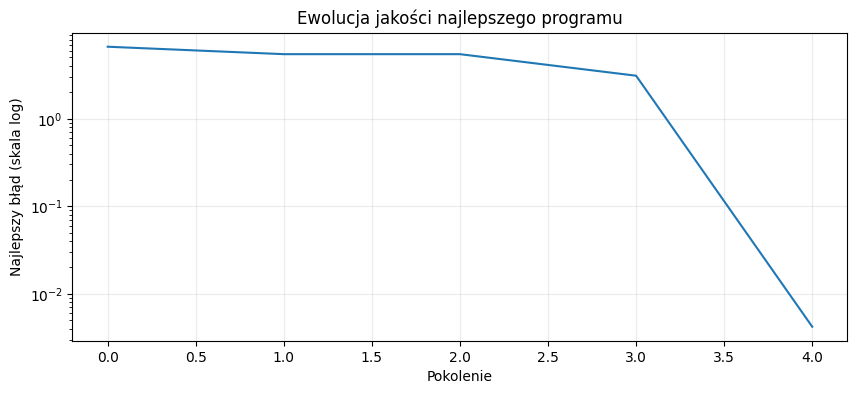

In [9]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 4))
plt.plot(history)
plt.yscale("log")
plt.xlabel("Pokolenie")
plt.ylabel("Najlepszy błąd (skala log)")
plt.title("Ewolucja jakości najlepszego programu")
plt.grid(True, alpha=0.25)
plt.show()